In [1]:
import os
import torch

print("Thư mục:", os.getcwd())
print("Kaggle runtime:", os.environ.get("KAGGLE_KERNEL_RUN_TYPE"))
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Tính thử:", torch.ones(10, device="cuda").sum().item())

Thư mục: /kaggle/working
Kaggle runtime: Interactive
CUDA: True
GPU: Tesla T4
Tính thử: 10.0


In [2]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi

token = UserSecretsClient().get_secret("HF_TOKEN")
account = HfApi().whoami(token=token)
print("Tài khoản Hugging Face:", account["name"])

Tài khoản Hugging Face: minhE10


In [3]:
from pathlib import Path
import zipfile
from huggingface_hub import hf_hub_download

zip_path = hf_hub_download(
    repo_id="deepghs/nsfw_detect",
    filename="nsfw_dataset_v1.zip",
    repo_type="dataset",
    token=token,
)

extract_dir = Path("/kaggle/working/nsfw_dataset")
dataset_dir = extract_dir / "nsfw_dataset_v1"
extract_dir.mkdir(parents=True, exist_ok=True)

if not dataset_dir.exists():
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(extract_dir)

for label in ["drawings", "hentai", "neutral", "porn", "sexy"]:
    count = len(list((dataset_dir / label).glob("*.jpg")))
    print(f"{label}: {count} ảnh")
    if count < 400:
        raise ValueError(f"Lớp {label} chưa đủ ảnh cho benchmark")

drawings: 5600 ảnh
hentai: 5600 ảnh
neutral: 5600 ảnh
porn: 5600 ảnh
sexy: 5600 ảnh


## Thí nghiệm zero-shot: MobileCLIP2-S0 và SigLIP2 Base

Ba cell phía trên đã kiểm tra được **Kaggle / Tesla T4**, xác thực `HF_TOKEN` và tải
`deepghs/nsfw_detect` (5.600 ảnh mỗi lớp). Output đó là kết quả của phiên đã lưu;
phiên mới vẫn cần chạy lại các cell. Không in hoặc lưu token vào kết quả.

**Cách chạy:** bật Internet, chọn GPU T4, bật quyền truy cập secret `HF_TOKEN`, rồi
chạy từ trên xuống. Cell cài đặt có thể yêu cầu **Restart kernel/session** một lần
nếu thay đổi thư viện đã import; sau đó chạy lại từ đầu. Giữ Torch/CUDA của Kaggle.

Hai model dùng embedding ảnh–văn bản, **không fine-tune, không dùng nhãn benchmark
để chọn prompt hoặc ngưỡng**. Mỗi lớp có hai prompt tiếng Anh cố định. Chuẩn hóa
embedding từng prompt, lấy trung bình theo lớp rồi chuẩn hóa lại. Dùng logit scale
của checkpoint và softmax trên 5 lớp; `score_nsfw = p(hentai)+p(porn)+p(sexy)`.
Điểm này là điểm tương đối theo bộ prompt, **không phải xác suất NSFW đã hiệu chỉnh**.
SigLIP vốn dùng sigmoid cho từng cặp ảnh–văn bản; ở đây áp dụng softmax 5 lớp như một
quy tắc quyết định chung, không cộng các sigmoid độc lập thành xác suất.

Đo cùng protocol cũ: 2.000 ảnh, 400/lớp, seed 42, batch 1, FP32, warm-up 3,
ngưỡng 0,5. Thời gian mỗi ảnh gồm đọc ảnh, tiền xử lý, image encoder và tính điểm;
không gồm tải model, tạo embedding văn bản hay warm-up. Đây là thời gian end-to-end
của từng ảnh, không phải throughput tối đa khi batching. Chạy lần lượt, giải phóng
model khỏi GPU sau mỗi lần. Không hiển thị ảnh nhạy cảm.

Nguồn: [Apple MobileCLIP](https://github.com/apple-aiml-research/ml-mobileclip),
[checkpoint OpenCLIP](https://huggingface.co/timm/MobileCLIP2-S0-OpenCLIP),
[SigLIP2](https://huggingface.co/google/siglip2-base-patch16-224),
[dataset](https://huggingface.co/datasets/deepghs/nsfw_detect).
MobileCLIP2-S0 dùng đầu vào **256×256**, SigLIP2 Base dùng **224×224** theo processor
của checkpoint. Kiểm tra giấy phép model và dataset trước khi chia sẻ/triển khai.

In [4]:
import importlib.metadata as metadata
import subprocess
import sys

# Không thay Torch / torchvision / CUDA đã hoạt động trong kernel Kaggle.
# Các phiên bản này được kiểm tra API trong quá trình chuẩn bị notebook.
REQUIREMENTS = [
    "open_clip_torch==4.2.1", "transformers==5.22.1", "timm==1.0.31",
    "sentencepiece>=0.2,<0.3", "scikit-learn>=1.4,<2", "matplotlib>=3.7,<4",
    "pandas>=2,<4", "Pillow>=10", "psutil>=5.9", "tqdm>=4.66",
]
watched = {
    "huggingface-hub": "huggingface_hub", "timm": "timm",
    "transformers": "transformers", "open_clip_torch": "open_clip",
    "numpy": "numpy", "pandas": "pandas", "Pillow": "PIL",
    "tokenizers": "tokenizers", "safetensors": "safetensors",
}
before = {}
for distribution, module in watched.items():
    if module in sys.modules:
        try:
            before[distribution] = metadata.version(distribution)
        except metadata.PackageNotFoundError:
            pass
if tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2]) < (2, 6):
    raise RuntimeError("Cần kernel Kaggle có Torch >= 2.6; chọn image Kaggle mới trước khi chạy.")
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--disable-pip-version-check", *REQUIREMENTS,
])
changed = [name for name, old in before.items() if metadata.version(name) != old]
if changed:
    raise RuntimeError(
        f"Đã cập nhật thư viện đang được import: {changed}. "
        "Hãy Restart kernel/session, rồi chạy lại notebook từ đầu."
    )
print("Thư viện sẵn sàng. Torch:", torch.__version__)

Thư viện sẵn sàng. Torch: 2.11.0+cu128


In [5]:
import gc
import hashlib
import json
import platform
import random
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn.functional as F
from PIL import Image
from IPython.display import display, FileLink
from huggingface_hub import HfApi, snapshot_download
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve, precision_recall_curve,
)
from tqdm.auto import tqdm

BASE_DIR = Path('/kaggle/working')
DATASET_DIR = Path(dataset_dir)
BENCHMARK_PATH = BASE_DIR / 'benchmark_2000.csv'
OUTPUT_DIR = BASE_DIR / 'zero_shot_benchmark_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LABELS = ['drawings', 'hentai', 'neutral', 'porn', 'sexy']
NSFW_LABELS = {'hentai', 'porn', 'sexy'}
SEED, SAMPLES_PER_CLASS, BATCH_SIZE, WARMUP = 42, 400, 1, 3
THRESHOLD = 0.5
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
REQUIRE_REFERENCE_MATCH = True
REFERENCE_SHA256 = '261b3cca292d7cd6b31ba92ac20ad93c7336c11bb7779b2012d48a1104457f3b'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == 'cuda':
    torch.cuda.set_device(DEVICE)
    torch.cuda.manual_seed_all(SEED)
    # Giữ phép nhân FP32, không dùng AMP / TF32 để so với protocol trước.
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False
print('Thiết bị:', DEVICE,
      torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else '(chạy CPU)')
print('Kết quả:', OUTPUT_DIR)

# Chốt trước khi suy luận; không sửa theo kết quả benchmark.
PROMPTS = {
    'drawings': [
        'a non-sexual drawing or cartoon with no nudity.',
        'a safe illustration or artwork without sexual content.',
    ],
    'hentai': [
        'an explicit sexual anime or manga illustration.',
        'a pornographic cartoon depicting nudity or sexual activity.',
    ],
    'neutral': [
        'an ordinary non-sexual photograph of everyday life.',
        'a safe photograph of people, objects, or scenery without sexual content.',
    ],
    'porn': [
        'an explicit pornographic photograph depicting adult nudity or sexual activity.',
        'a sexually explicit photograph with exposed genitals or sexual intercourse.',
    ],
    'sexy': [
        'a sexually suggestive photograph of an adult in lingerie or revealing clothing.',
        'an erotic photograph of an adult posing in underwear or a swimsuit.',
    ],
}
FLAT_PROMPTS = [prompt for label in LABELS for prompt in PROMPTS[label]]
PROMPTS_SHA256 = hashlib.sha256(
    json.dumps(PROMPTS, ensure_ascii=False, sort_keys=True).encode('utf-8')
).hexdigest()
MODEL_SPECS = {
    'MobileCLIP2-S0': {
        'repo_id': 'timm/MobileCLIP2-S0-OpenCLIP', 'revision': 'main',
        'image_size': 256,
    },
    'SigLIP2-Base': {
        'repo_id': 'google/siglip2-base-patch16-224', 'revision': 'main',
        'image_size': 224,
    },
}
# Lần đầu resolve main -> commit SHA; environment.json ghi SHA để tái lập.
# Muốn tái lập checkpoint ở phiên sau: thay revision='main' bằng SHA đã lưu.
RUN_STARTED = datetime.now(timezone.utc).isoformat()
all_predictions, performance_rows, model_records = {}, {}, {}

Thiết bị: cuda:0 Tesla T4
Kết quả: /kaggle/working/zero_shot_benchmark_results


### Cố định và xác thực benchmark

Dùng lại `benchmark_2000.csv` nếu có; nếu chưa có, tạo bằng đúng sampler cũ.
Kiểm tra giải mã ảnh và SHA256 toàn bộ dữ liệu trước khi đo tốc độ. Fingerprint
phải khớp lần chạy ba model; nếu khác, dừng để tránh so sánh trên hai tập ảnh khác nhau.
Chỉ đặt `REQUIRE_REFERENCE_MATCH=False` khi chủ động tạo một thí nghiệm khác.

In [6]:
def make_benchmark(root, labels, n, seed):
    rng = random.Random(seed)
    rows = []
    for label in labels:
        paths = sorted((Path(root) / label).glob('*.jpg'))
        if len(paths) < n:
            raise ValueError(f'{label}: chỉ có {len(paths)} ảnh, cần {n}.')
        rows.extend({'image_path': str(p), 'true_label': label}
                    for p in rng.sample(paths, n))
    return pd.DataFrame(rows).sample(frac=1, random_state=seed).reset_index(drop=True)


def audit_benchmark(frame, root, labels, n):
    required = {'image_path', 'true_label'}
    if not required.issubset(frame.columns):
        raise ValueError(f'Benchmark thiếu cột {required - set(frame.columns)}')
    frame = frame[['image_path', 'true_label']].copy().reset_index(drop=True)
    if frame.isna().any().any():
        raise ValueError('CSV có đường dẫn hoặc nhãn trống.')
    if frame.true_label.value_counts().to_dict() != {label: n for label in labels}:
        raise ValueError('CSV phải có đúng số ảnh mỗi lớp, giữ nguyên tên 5 lớp.')
    rows = []
    root = Path(root).resolve()
    for row in tqdm(frame.itertuples(index=False), total=len(frame), desc='Audit ảnh'):
        path = Path(row.image_path).resolve()
        relative = path.relative_to(root)
        if relative.parts[0] != row.true_label:
            raise ValueError(f'Nhãn không khớp thư mục: {relative}')
        with Image.open(path) as image:
            image.load()
            width, height = image.size
        rows.append(dict(image_path=str(path), true_label=row.true_label,
                         image_id=relative.as_posix(), width=width, height=height,
                         sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    audited = pd.DataFrame(rows)
    if audited.image_id.duplicated().any():
        raise ValueError('CSV có cùng ảnh lặp lại.')
    if audited.groupby('sha256').true_label.nunique().gt(1).any():
        raise ValueError('Có ảnh giống nội dung nhưng khác nhãn.')
    audited['y_true'] = audited.true_label.isin(NSFW_LABELS).astype(int)
    signature = '\n'.join(
        f'{row.image_id}|{row.true_label}|{row.sha256}'
        for row in audited.itertuples(index=False)
    )
    return audited, hashlib.sha256(signature.encode('utf-8')).hexdigest()


if BENCHMARK_PATH.exists():
    benchmark_source = pd.read_csv(BENCHMARK_PATH)
    print('Dùng lại:', BENCHMARK_PATH)
else:
    benchmark_source = make_benchmark(DATASET_DIR, LABELS, SAMPLES_PER_CLASS, SEED)
    benchmark_source.to_csv(BENCHMARK_PATH, index=False)
    print('Đã tạo:', BENCHMARK_PATH)
benchmark_df, BENCHMARK_SHA256 = audit_benchmark(
    benchmark_source, DATASET_DIR, LABELS, SAMPLES_PER_CLASS,
)
if REQUIRE_REFERENCE_MATCH and BENCHMARK_SHA256 != REFERENCE_SHA256:
    raise ValueError(
        f'Fingerprint khác benchmark cũ: {BENCHMARK_SHA256}. '
        'Kiểm tra dataset / benchmark_2000.csv; chưa được so sánh trực tiếp với 3 model cũ.'
    )
benchmark_df.to_csv(OUTPUT_DIR / 'benchmark_audit.csv', index=False)
benchmark_df[['image_path', 'true_label']].to_csv(OUTPUT_DIR / 'benchmark_2000.csv', index=False)
(OUTPUT_DIR / 'prompts.json').write_text(
    json.dumps(PROMPTS, ensure_ascii=False, indent=2), encoding='utf-8',
)
print('Fingerprint:', BENCHMARK_SHA256)
print('Khớp lần chạy trước:', BENCHMARK_SHA256 == REFERENCE_SHA256)
print('Ảnh trùng nội dung (giữ nguyên mẫu cũ):', int(benchmark_df.sha256.duplicated().sum()))
display(benchmark_df.groupby('true_label').agg(n_images=('image_id', 'size'),
                                            min_width=('width', 'min'),
                                            min_height=('height', 'min')))
print('NSFW:', int(benchmark_df.y_true.sum()), '| SFW:', int((benchmark_df.y_true == 0).sum()))

Đã tạo: /kaggle/working/benchmark_2000.csv


Audit ảnh:   0%|          | 0/2000 [00:00<?, ?it/s]

Fingerprint: 261b3cca292d7cd6b31ba92ac20ad93c7336c11bb7779b2012d48a1104457f3b
Khớp lần chạy trước: True
Ảnh trùng nội dung (giữ nguyên mẫu cũ): 0


,n_images,min_width,min_height
true_label,,,
drawings,400,236,236
hentai,400,305,240
neutral,400,416,270
porn,400,443,480
sexy,400,394,431


NSFW: 1200 | SFW: 800


In [7]:
def sync_device():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize(DEVICE)


def release_device():
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()


def pooled_features(output):
    # Transformers 4.x thường trả Tensor, 5.x có thể trả ModelOutput.
    features = output if isinstance(output, torch.Tensor) else getattr(output, 'pooler_output', None)
    if not isinstance(features, torch.Tensor) or features.ndim != 2:
        raise TypeError('Cần embedding pooled [batch, dimension], không dùng hidden states.')
    return features.float()


def class_prototypes(text_features):
    features = F.normalize(pooled_features(text_features), dim=-1)
    expected = sum(len(PROMPTS[label]) for label in LABELS)
    if features.shape[0] != expected:
        raise ValueError('Số embedding không khớp prompt.')
    prototypes, offset = [], 0
    for label in LABELS:
        count = len(PROMPTS[label])
        prototypes.append(F.normalize(features[offset:offset + count].mean(dim=0), dim=0))
        offset += count
    return torch.stack(prototypes)


def score_features(image_features, prototypes, logit_scale, logit_bias=None):
    images = F.normalize(pooled_features(image_features), dim=-1)
    logits = logit_scale.exp().float() * (images @ prototypes.T)
    if logit_bias is not None:
        logits = logits + logit_bias.float()
    return torch.softmax(logits, dim=-1)


def checked_scores(values, n):
    probabilities = np.asarray(values, dtype=np.float64)
    if probabilities.shape != (n, len(LABELS)):
        raise ValueError(f'Sai shape điểm: {probabilities.shape}')
    if (not np.isfinite(probabilities).all() or (probabilities < 0).any()
            or (probabilities > 1).any()
            or not np.allclose(probabilities.sum(axis=1), 1., atol=1e-5)):
        raise ValueError('Điểm không hợp lệ; không bỏ âm thầm ảnh lỗi.')
    return probabilities


def checkpoint_snapshot(spec, mobile=False):
    api = HfApi(token=token)
    info = api.model_info(spec['repo_id'], revision=spec['revision'])
    # Chỉ tải safetensors; không tải thêm bản .bin/.pt trùng trọng số.
    patterns = ['*.json', '*.txt', '*.model', '*.safetensors', 'README.md', 'LICENSE*']
    directory = Path(snapshot_download(
        spec['repo_id'], revision=info.sha, token=token, allow_patterns=patterns,
    ))
    weights = sorted(directory.glob('*.safetensors'))
    if not weights:
        raise FileNotFoundError(f'Không tìm thấy safetensors trong {spec["repo_id"]}.')
    if mobile and not (directory / 'open_clip_config.json').is_file():
        raise FileNotFoundError('Checkpoint MobileCLIP thiếu open_clip_config.json.')
    sizes, digests = {}, {}
    for path in weights:
        digest = hashlib.sha256()
        with path.open('rb') as stream:
            for chunk in iter(lambda: stream.read(1024 * 1024), b''):
                digest.update(chunk)
        sizes[path.name], digests[path.name] = path.stat().st_size, digest.hexdigest()
    return directory, dict(repo_id=spec['repo_id'], revision=info.sha,
                           checkpoint_sha256=digests, checkpoint_mb=sum(sizes.values()) / 1024**2)


def environment_record():
    packages = {}
    for name in ['torch', 'torchvision', 'open_clip_torch', 'transformers', 'timm',
                 'huggingface-hub', 'tokenizers', 'numpy', 'pandas', 'Pillow',
                 'scikit-learn', 'matplotlib', 'sentencepiece', 'psutil']:
        try:
            packages[name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            packages[name] = None
    return dict(
        run_started_utc=RUN_STARTED, updated_utc=datetime.now(timezone.utc).isoformat(),
        python=platform.python_version(), platform=platform.platform(), packages=packages,
        device=str(DEVICE), gpu=torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else None,
        torch_cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
        batch_size=BATCH_SIZE, precision='FP32', warmup_images=WARMUP,
        seed=SEED, samples_per_class=SAMPLES_PER_CLASS, labels=LABELS,
        nsfw_labels=sorted(NSFW_LABELS), threshold=THRESHOLD,
        benchmark_sha256=BENCHMARK_SHA256, reference_sha256=REFERENCE_SHA256,
        reference_matches=(BENCHMARK_SHA256 == REFERENCE_SHA256),
        prompts_sha256=PROMPTS_SHA256, scoring='normalized mean text prototypes; 5-way softmax; sum NSFW',
        timing='batch=1; synchronized decode+preprocess+image encoder+scoring+CPU transfer; text cached',
        models=model_records,
    )


def run_benchmark(name, predict_one, model_info):
    if BATCH_SIZE != 1:
        raise ValueError('Runner này chỉ đo batch=1 theo protocol cũ.')
    # Warm-up toàn pipeline; không đưa vào thống kê.
    with torch.inference_mode():
        for i in range(WARMUP):
            predict_one(Path(benchmark_df.iloc[i % len(benchmark_df)].image_path))
        sync_device()
        if DEVICE.type == 'cuda':
            torch.cuda.reset_peak_memory_stats(DEVICE)
        values, milliseconds = [], []
        for row in tqdm(benchmark_df.itertuples(index=False), total=len(benchmark_df), desc=name):
            sync_device()
            started = time.perf_counter()
            scores = predict_one(Path(row.image_path))  # includes tensor -> CPU
            sync_device()
            elapsed = (time.perf_counter() - started) * 1000
            values.append(scores)
            milliseconds.append(elapsed)
    probabilities = checked_scores(values, len(benchmark_df))
    predictions = benchmark_df[['image_id', 'image_path', 'true_label', 'y_true']].copy()
    for i, label in enumerate(LABELS):
        predictions[f'p_{label}'] = probabilities[:, i]
    predictions['predicted_label'] = np.asarray(LABELS)[probabilities.argmax(axis=1)]
    nsfw_columns = [LABELS.index(label) for label in LABELS if label in NSFW_LABELS]
    predictions['score_nsfw'] = probabilities[:, nsfw_columns].sum(axis=1)
    predictions['y_pred'] = (predictions.score_nsfw >= THRESHOLD).astype(int)
    predictions['latency_ms'] = milliseconds
    predictions['benchmark_sha256'] = BENCHMARK_SHA256
    predictions['prompts_sha256'] = PROMPTS_SHA256
    times = np.asarray(milliseconds)
    peak = torch.cuda.max_memory_allocated(DEVICE) / 1024**2 if DEVICE.type == 'cuda' else np.nan
    performance = dict(
        model=name, n_images=len(predictions), device=str(DEVICE), precision='FP32', batch_size=1,
        mean_latency_ms=float(times.mean()), median_latency_ms=float(np.median(times)),
        p95_latency_ms=float(np.percentile(times, 95)),
        throughput_img_s=float(1000. / times.mean()), total_inference_s=float(times.sum() / 1000.),
        peak_gpu_allocated_mb=peak, process_rss_after_mb=psutil.Process().memory_info().rss / 1024**2,
        **{key: model_info[key] for key in ['setup_s', 'text_cache_s', 'parameters_m',
                                           'vision_parameters_m', 'checkpoint_mb', 'image_size']},
    )
    # Lưu ngay sau từng model để không mất model đầu nếu model sau lỗi.
    slug = name.lower().replace('-', '_')
    predictions.to_csv(OUTPUT_DIR / f'predictions_{slug}.csv', index=False)
    all_predictions[name], performance_rows[name], model_records[name] = predictions, performance, model_info
    pd.DataFrame(performance_rows.values()).to_csv(OUTPUT_DIR / 'performance_metrics.csv', index=False)
    (OUTPUT_DIR / 'environment.json').write_text(
        json.dumps(environment_record(), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8',
    )
    display(pd.DataFrame([performance]).round(3))
    return predictions

### 1. MobileCLIP2-S0

Dùng bản safetensors do OpenCLIP/timm phát hành, ghim revision bằng commit SHA.
Đọc cả cấu hình và processor của checkpoint. Reparameterize các nhánh FastViT
cho inference bằng helper của timm; kiểm tra embedding trước/sau để phát hiện sai lệch.
Embedding văn bản được tính một lần, ngoài vòng đo từng ảnh.

In [8]:
import open_clip
from timm.utils import reparameterize_model


def benchmark_mobileclip():
    name = 'MobileCLIP2-S0'
    spec = MODEL_SPECS[name]
    release_device()
    started = time.perf_counter()
    directory, record = checkpoint_snapshot(spec, mobile=True)
    local_name = f'local-dir:{directory}'
    model, _, preprocess = open_clip.create_model_and_transforms(
        local_name, device=DEVICE, precision='fp32',
    )
    model.eval()
    tokenizer = open_clip.get_tokenizer(local_name)
    parameters = sum(p.numel() for p in model.parameters()) / 1e6
    vision_parameters = sum(p.numel() for p in model.visual.parameters()) / 1e6
    # Kiểm tra reparameterization trên ảnh không phụ thuộc nhãn, ngoài thời gian đo.
    with Image.open(benchmark_df.iloc[0].image_path) as image:
        probe = preprocess(image.convert('RGB')).unsqueeze(0).to(DEVICE)
    if tuple(probe.shape[-2:]) != (spec['image_size'], spec['image_size']):
        raise ValueError(f'Đầu vào MobileCLIP không đúng cấu hình: {probe.shape}')
    with torch.inference_mode():
        before_reparam = model.encode_image(probe, normalize=True)
        # Chỉ thay image backbone, giữ text encoder và logit scale của checkpoint.
        model.visual = reparameterize_model(model.visual, inplace=True)
        model.eval()
        after_reparam = model.encode_image(probe, normalize=True)
        torch.testing.assert_close(before_reparam, after_reparam, rtol=3e-3, atol=3e-4)
        sync_device()
        text_started = time.perf_counter()
        tokens = tokenizer(FLAT_PROMPTS).to(DEVICE)
        prototypes = class_prototypes(model.encode_text(tokens, normalize=True))
        sync_device()
        text_cache_s = time.perf_counter() - text_started
    record.update(parameters_m=parameters, vision_parameters_m=vision_parameters,
                  image_size=spec['image_size'], reparameterized=True,
                  preprocess=str(preprocess), text_cache_s=text_cache_s,
                  setup_s=time.perf_counter() - started)

    @torch.inference_mode()
    def predict_one(path):
        with Image.open(path) as image:
            inputs = preprocess(image.convert('RGB')).unsqueeze(0).to(DEVICE)
        image_features = model.encode_image(inputs, normalize=True)
        scores = score_features(image_features, prototypes, model.logit_scale,
                                getattr(model, 'logit_bias', None))
        return scores[0].float().cpu().numpy()

    try:
        return run_benchmark(name, predict_one, record)
    finally:
        del predict_one, prototypes, tokens, probe, before_reparam, after_reparam, model
        release_device()


mobile_predictions = benchmark_mobileclip()
release_device()  # sau khi frame hàm và closure đã giải phóng

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

MobileCLIP2-S0:   0%|          | 0/2000 [00:00<?, ?it/s]

,model,n_images,device,precision,batch_size,mean_latency_ms,median_latency_ms,p95_latency_ms,throughput_img_s,total_inference_s,peak_gpu_allocated_mb,process_rss_after_mb,setup_s,text_cache_s,parameters_m,vision_parameters_m,checkpoint_mb,image_size
0,MobileCLIP2-S0,2000,cuda:0,FP32,1,17.417,17.306,19.871,57.414,34.835,309.318,1776.668,10.074,0.178,74.835,11.407,285.781,256


### 2. SigLIP2 Base patch16 224

Sử dụng AutoProcessor/AutoModel cục bộ từ snapshot đã ghim SHA, không chạy remote code.
Token hóa văn bản chữ thường với `padding='max_length', max_length=64` theo model card.
Kiểm tra logits từ embedding cache khớp full forward trên một ảnh trước khi benchmark.

In [9]:
from transformers import AutoModel, AutoProcessor


def benchmark_siglip():
    name = 'SigLIP2-Base'
    spec = MODEL_SPECS[name]
    release_device()
    started = time.perf_counter()
    directory, record = checkpoint_snapshot(spec)
    processor = AutoProcessor.from_pretrained(directory, local_files_only=True, trust_remote_code=False)
    model = AutoModel.from_pretrained(
        directory, local_files_only=True, trust_remote_code=False,
    ).to(device=DEVICE, dtype=torch.float32).eval()
    parameters = sum(p.numel() for p in model.parameters()) / 1e6
    vision_parameters = sum(p.numel() for p in model.vision_model.parameters()) / 1e6
    texts = [text.lower() for text in FLAT_PROMPTS]
    with torch.inference_mode():
        sync_device()
        text_started = time.perf_counter()
        text_inputs = processor.tokenizer(
            texts, padding='max_length', max_length=64, truncation=True, return_tensors='pt',
        ).to(DEVICE)
        text_features = pooled_features(model.get_text_features(**text_inputs))
        prototypes = class_prototypes(text_features)
        sync_device()
        text_cache_s = time.perf_counter() - text_started
        # Kiểm chứng API pooled_features và normalization/scale/bias ngoài vòng đo.
        with Image.open(benchmark_df.iloc[0].image_path) as image:
            image_inputs = processor.image_processor(images=image.convert('RGB'), return_tensors='pt').to(DEVICE)
        if tuple(image_inputs['pixel_values'].shape[-2:]) != (spec['image_size'], spec['image_size']):
            raise ValueError('Processor SigLIP2 không trả đúng kích thước 224x224.')
        image_features = pooled_features(model.get_image_features(**image_inputs))
        cached_logits = model.logit_scale.exp() * (
            F.normalize(image_features, dim=-1) @ F.normalize(text_features, dim=-1).T
        ) + model.logit_bias
        full_logits = model(**image_inputs, **text_inputs).logits_per_image
        torch.testing.assert_close(cached_logits, full_logits.float(), rtol=2e-3, atol=2e-3)
        sync_device()
    record.update(parameters_m=parameters, vision_parameters_m=vision_parameters,
                  image_size=spec['image_size'], reparameterized=False,
                  processor=processor.to_dict() if hasattr(processor, 'to_dict') else str(processor),
                  text_max_length=64, text_cache_s=text_cache_s,
                  setup_s=time.perf_counter() - started)

    @torch.inference_mode()
    def predict_one(path):
        with Image.open(path) as image:
            inputs = processor.image_processor(images=image.convert('RGB'), return_tensors='pt').to(DEVICE)
        features = model.get_image_features(**inputs)
        scores = score_features(features, prototypes, model.logit_scale, model.logit_bias)
        return scores[0].float().cpu().numpy()

    try:
        return run_benchmark(name, predict_one, record)
    finally:
        del predict_one, model, prototypes, text_features, text_inputs
        del image_features, image_inputs, cached_logits, full_logits
        release_device()


siglip_predictions = benchmark_siglip()
release_device()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

SigLIP2-Base:   0%|          | 0/2000 [00:00<?, ?it/s]

,model,n_images,device,precision,batch_size,mean_latency_ms,median_latency_ms,p95_latency_ms,throughput_img_s,total_inference_s,peak_gpu_allocated_mb,process_rss_after_mb,setup_s,text_cache_s,parameters_m,vision_parameters_m,checkpoint_mb,image_size
0,SigLIP2-Base,2000,cuda:0,FP32,1,20.179,20.138,22.518,49.558,40.357,1448.449,2114.328,18.481,0.05,375.188,92.884,1431.275,224


### So sánh chất lượng và tốc độ

Metric chính là phân loại nhị phân SFW/NSFW. Với quy ước cũ, lớp `sexy` (gồm nhiều
ảnh không khỏa thân) vẫn là NSFW; do đó kết quả này không đồng nghĩa khả năng phát
hiện khỏa thân thuần túy. Recall theo từng lớp giúp thấy model bỏ sót loại nào.
Thêm accuracy/F1 macro 5 lớp để tham khảo; không chọn lại prompt/ngưỡng sau khi xem.
Không có kiểm soát overlap giữa pretraining của các model và benchmark này.

`peak_gpu_allocated_mb` là peak của bộ cấp phát Torch, không phải toàn bộ VRAM từ
`nvidia-smi`; `process_rss_after_mb` là RAM tiến trình sau chạy, không phải peak RAM.
Tốc độ chạy nối tiếp có đồng bộ GPU và CPU transfer, không suy ra trực tiếp latency
của một dịch vụ có concurrency hoặc cache ảnh khác.

Chất lượng nhị phân (NSFW = hentai + porn + sexy):


,model,threshold,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp,accuracy_5class,f1_macro_5class
0,MobileCLIP2-S0,0.5,0.3405,0.4184,0.2542,0.3162,0.3143,0.481,376,424,895,305,0.203,0.1577
1,SigLIP2-Base,0.5,0.8285,0.8857,0.8200,0.8516,0.9123,0.930,673,127,216,984,0.755,0.7558


Tốc độ end-to-end, batch=1, FP32:


,model,n_images,device,precision,batch_size,mean_latency_ms,median_latency_ms,p95_latency_ms,throughput_img_s,total_inference_s,peak_gpu_allocated_mb,process_rss_after_mb,setup_s,text_cache_s,parameters_m,vision_parameters_m,checkpoint_mb,image_size
0,MobileCLIP2-S0,2000,cuda:0,FP32,1,17.417,17.306,19.871,57.414,34.835,309.318,1776.668,10.074,0.178,74.835,11.407,285.781,256
1,SigLIP2-Base,2000,cuda:0,FP32,1,20.179,20.138,22.518,49.558,40.357,1448.449,2114.328,18.481,0.050,375.188,92.884,1431.275,224


Phân tích từng lớp:


,model,true_label,n_images,expected_nsfw,nsfw_detection_rate,binary_accuracy,mean_nsfw_score
0,MobileCLIP2-S0,drawings,400,0,0.6175,0.3825,0.5333
1,MobileCLIP2-S0,hentai,400,1,0.4475,0.4475,0.4891
2,MobileCLIP2-S0,neutral,400,0,0.4425,0.5575,0.4752
3,MobileCLIP2-S0,porn,400,1,0.0600,0.0600,0.3130
4,MobileCLIP2-S0,sexy,400,1,0.2550,0.2550,0.4045
5,SigLIP2-Base,drawings,400,0,0.1725,0.8275,0.2998
6,SigLIP2-Base,hentai,400,1,0.6300,0.6300,0.5698
7,SigLIP2-Base,neutral,400,0,0.1450,0.8550,0.2090
8,SigLIP2-Base,porn,400,1,0.9475,0.9475,0.8714
9,SigLIP2-Base,sexy,400,1,0.8825,0.8825,0.8163


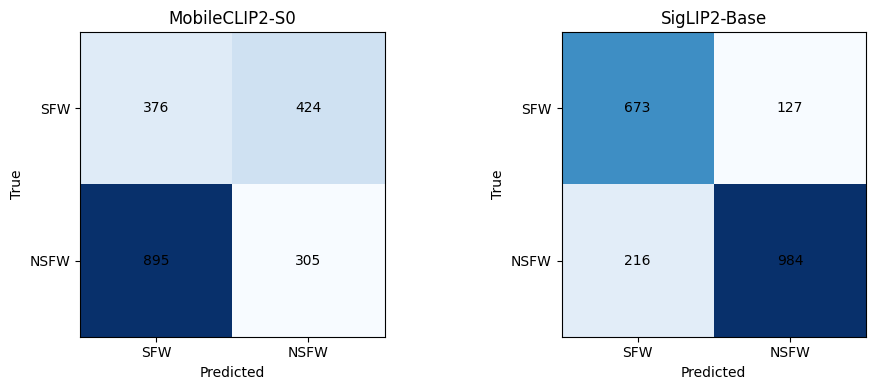

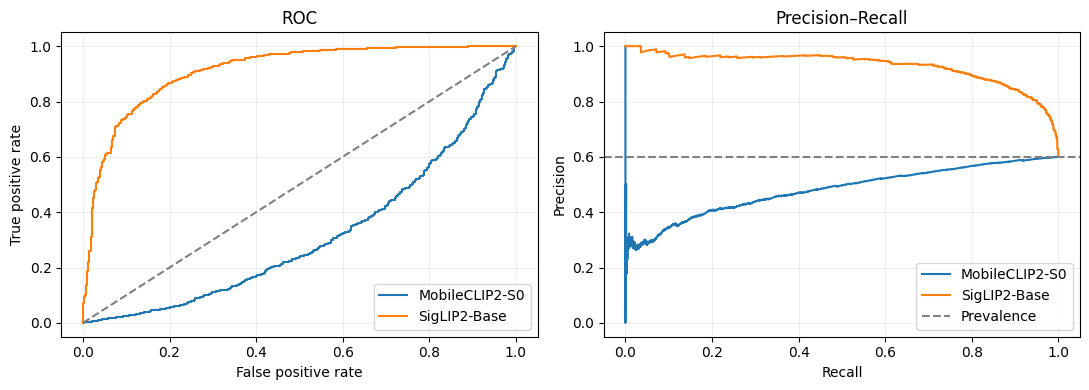

In [10]:
if set(all_predictions) != set(MODEL_SPECS):
    raise RuntimeError('Cần chạy thành công cả hai cell model trước khi tổng hợp.')
quality_rows, class_rows = [], []
for name, frame in all_predictions.items():
    if frame.image_id.tolist() != benchmark_df.image_id.tolist():
        raise ValueError(f'{name}: thứ tự hoặc số ảnh không trùng benchmark.')
    y, pred, scores = frame.y_true, frame.y_pred, frame.score_nsfw
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    quality_rows.append(dict(
        model=name, threshold=THRESHOLD, accuracy=accuracy_score(y, pred),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        f1=f1_score(y, pred, zero_division=0), roc_auc=roc_auc_score(y, scores),
        average_precision=average_precision_score(y, scores),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
        accuracy_5class=accuracy_score(frame.true_label, frame.predicted_label),
        f1_macro_5class=f1_score(frame.true_label, frame.predicted_label,
                               labels=LABELS, average='macro', zero_division=0),
    ))
    for label in LABELS:
        subset = frame[frame.true_label == label]
        is_nsfw = label in NSFW_LABELS
        class_rows.append(dict(model=name, true_label=label, n_images=len(subset),
                               expected_nsfw=int(is_nsfw),
                               nsfw_detection_rate=float(subset.y_pred.mean()),
                               binary_accuracy=float((subset.y_pred == int(is_nsfw)).mean()),
                               mean_nsfw_score=float(subset.score_nsfw.mean())))

quality_df = pd.DataFrame(quality_rows)
performance_df = pd.DataFrame(performance_rows.values())
per_class_df = pd.DataFrame(class_rows)
comparison_df = quality_df.merge(performance_df, on='model', validate='one_to_one')
for filename, frame in [('quality_metrics.csv', quality_df),
                        ('performance_metrics.csv', performance_df),
                        ('per_class_metrics.csv', per_class_df),
                        ('comparison.csv', comparison_df)]:
    frame.to_csv(OUTPUT_DIR / filename, index=False)
print('Chất lượng nhị phân (NSFW = hentai + porn + sexy):')
display(quality_df.round(4))
print('Tốc độ end-to-end, batch=1, FP32:')
display(performance_df.round(3))
print('Phân tích từng lớp:')
display(per_class_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, frame) in zip(axes, all_predictions.items()):
    cm = confusion_matrix(frame.y_true, frame.y_pred, labels=[0, 1])
    ax.imshow(cm, cmap='Blues')
    for (i, j), count in np.ndenumerate(cm):
        ax.text(j, i, str(count), ha='center', va='center')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['SFW', 'NSFW'],
           yticklabels=['SFW', 'NSFW'], xlabel='Predicted', ylabel='True', title=name)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'confusion_matrices.png', dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, frame in all_predictions.items():
    fpr, tpr, _ = roc_curve(frame.y_true, frame.score_nsfw)
    precision, recall, _ = precision_recall_curve(frame.y_true, frame.score_nsfw)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[1].axhline(benchmark_df.y_true.mean(), linestyle='--', color='gray', label='Prevalence')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'roc_pr_curves.png', dpi=160)
plt.show()

### Tùy chọn: nối bảng với ba model cũ

Không cần chạy cell này để hoàn thành hai model mới. Nếu đã chép thư mục `results`
của lần chạy cũ vào Kaggle, đặt `PREVIOUS_RESULTS_DIR` bên dưới. Chỉ nối khi provenance
xác nhận cùng fingerprint. Bảng cũ đã làm tròn; tốc độ giữa hai phiên còn phụ thuộc
GPU/runtime và thư viện, cần kiểm tra riêng trước khi kết luận model nào nhanh hơn.

In [11]:
PREVIOUS_RESULTS_DIR = None  # ví dụ Path('/kaggle/input/your-upload/results')
if PREVIOUS_RESULTS_DIR is not None:
    previous_dir = Path(PREVIOUS_RESULTS_DIR)
    provenance = json.loads((previous_dir / 'provenance.json').read_text(encoding='utf-8'))
    previous_fingerprint = provenance.get('benchmark_sha256')
    if previous_fingerprint != BENCHMARK_SHA256:
        raise ValueError('Provenance lần chạy cũ thiếu fingerprint hoặc không cùng benchmark.')
    old_quality = pd.read_csv(previous_dir / 'quality_metrics.csv')
    old_quality['run_group'] = 'previous_supervised'
    new_quality = quality_df.copy()
    new_quality['run_group'] = 'new_zero_shot'
    combined_quality = pd.concat([old_quality, new_quality], ignore_index=True, sort=False)
    combined_quality.to_csv(OUTPUT_DIR / 'comparison_with_previous_quality.csv', index=False)
    display(combined_quality)
else:
    print('Bỏ qua bảng cũ; kết quả hai model mới đã lưu riêng.')

Bỏ qua bảng cũ; kết quả hai model mới đã lưu riêng.


### Lưu và tải kết quả

Toàn bộ CSV, biểu đồ, cấu hình prompt, SHA checkpoint và phiên bản thư viện nằm ở
`/kaggle/working/zero_shot_benchmark_results/`. Cell dưới tạo ZIP để tải. Không đóng gói
ảnh dataset, trọng số hay token. Trong Kaggle dùng Save Version / Save & Run All
(lưu outputs); nếu chỉ sửa file ở VS Code, file chưa tự xuất hiện trên trang Kaggle.
Tải cả notebook `.ipynb` sau khi chạy để giữ output hiển thị.

In [12]:
(OUTPUT_DIR / 'environment.json').write_text(
    json.dumps(environment_record(), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8',
)
archive = Path(shutil.make_archive(str(BASE_DIR / 'zero_shot_benchmark_results'), 'zip', OUTPUT_DIR))
print('Kết quả:', OUTPUT_DIR)
print('ZIP:', archive)
print('Các file đã tạo:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f'  {path.name}: {path.stat().st_size:,} bytes')
display(FileLink(str(archive.relative_to(Path.cwd()))
                 if archive.is_relative_to(Path.cwd()) else str(archive)))

Kết quả: /kaggle/working/zero_shot_benchmark_results
ZIP: /kaggle/working/zero_shot_benchmark_results.zip
Các file đã tạo:
  benchmark_2000.csv: 243,024 bytes
  benchmark_audit.csv: 532,663 bytes
  comparison.csv: 1,119 bytes
  confusion_matrices.png: 33,574 bytes
  environment.json: 3,422 bytes
  per_class_metrics.csv: 680 bytes
  performance_metrics.csv: 722 bytes
  predictions_mobileclip2_s0.csv: 940,229 bytes
  predictions_siglip2_base.csv: 944,580 bytes
  prompts.json: 800 bytes
  quality_metrics.csv: 427 bytes
  roc_pr_curves.png: 89,245 bytes


/kaggle/working/zero_shot_benchmark_results.zip